In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Dataset location
possible_paths = [
    Path("Data/loan.csv"),
    Path("Assessment/Data/loan.csv")
]

csv_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if csv_path is None:
    raise FileNotFoundError("loan.csv file not found")

print("Dataset path:", csv_path)

Dataset path: Data\loan.csv


In [2]:
# Required columns
features = [
    "loan_amnt", "term", "int_rate", "installment", "grade",
    "emp_length", "home_ownership", "annual_inc",
    "verification_status", "purpose", "addr_state", "dti",
    "delinq_2yrs", "open_acc", "pub_rec", "revol_bal",
    "revol_util", "total_acc"
]

regression_features = [
    "annual_inc", "int_rate", "dti", "delinq_2yrs",
    "open_acc", "pub_rec", "revol_bal", "total_acc"
]

required_columns = list(set(
    features + regression_features + ["loan_status"]
))

# Load only required columns
df = pd.read_csv(
    csv_path,
    usecols=required_columns,
    low_memory=False
)

print("Dataset shape:", df.shape)
print("\nLoan status:")
print(df["loan_status"].value_counts().head(10))

Dataset shape: (2260668, 19)

Loan status:
loan_status
Fully Paid                                             1041952
Current                                                 919695
Charged Off                                             261655
Late (31-120 days)                                       21897
In Grace Period                                           8952
Late (16-30 days)                                         3737
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     31
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

# Keep only Fully Paid and Charged Off
df = df[df["loan_status"].isin(
    ["Fully Paid", "Charged Off"]
)].copy()

# Create target variable
df["target"] = df["loan_status"].map({
    "Fully Paid": 0,
    "Charged Off": 1
})

# Take 15% stratified sample
df = df.sample(
    frac=0.15,
    random_state=42
)

# Separate features and target
X = df[features]
y = df["target"]

# First split: 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

Training shape: (136878, 18)
Validation shape: (29331, 18)
Testing shape: (29332, 18)

Training target distribution:
target
0    0.797856
1    0.202144
Name: proportion, dtype: float64


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Separate numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["str", "object"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric columns:", numeric_features)
print("\nCategorical columns:", categorical_features)

Numeric columns: ['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'delinq_2yrs', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc']

Categorical columns: ['term', 'grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'addr_state']


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

print("Three classification models created successfully!")

Three classification models created successfully!


In [7]:
from sklearn.pipeline import Pipeline

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

print("\nAll models training completed!")

Logistic Regression trained successfully!
Random Forest trained successfully!
XGBoost trained successfully!

All models training completed!


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

for name, model in trained_models.items():

    y_pred = model.predict(X_val)

    print("\n", "=" * 40)
    print(name)
    print("=" * 40)

    print("Accuracy:", accuracy_score(y_val, y_pred))
    print("Precision:", precision_score(y_val, y_pred, zero_division=0))
    print("Recall:", recall_score(y_val, y_pred, zero_division=0))
    print("F1 Score:", f1_score(y_val, y_pred, zero_division=0))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_val, y_pred))


Logistic Regression
Accuracy: 0.6371415908083597
Precision: 0.313410386320456
Recall: 0.6677348625400573
F1 Score: 0.4265933947524379

Confusion Matrix:
[[14729  8673]
 [ 1970  3959]]

Random Forest
Accuracy: 0.7744366029115952
Precision: 0.4167272727272727
Recall: 0.2899308483724068
F1 Score: 0.3419534513626417

Confusion Matrix:
[[20996  2406]
 [ 4210  1719]]

XGBoost
Accuracy: 0.8004841294193856
Precision: 0.5606299212598426
Recall: 0.06004385225164446
F1 Score: 0.10847044485070079

Confusion Matrix:
[[23123   279]
 [ 5573   356]]


In [9]:
y_pred_xgb = trained_models["XGBoost"].predict(X_val)

print("XGBoost Accuracy:", accuracy_score(y_val, y_pred_xgb))
print("XGBoost Precision:", precision_score(y_val, y_pred_xgb, zero_division=0))
print("XGBoost Recall:", recall_score(y_val, y_pred_xgb, zero_division=0))
print("XGBoost F1 Score:", f1_score(y_val, y_pred_xgb, zero_division=0))

XGBoost Accuracy: 0.8004841294193856
XGBoost Precision: 0.5606299212598426
XGBoost Recall: 0.06004385225164446
XGBoost F1 Score: 0.10847044485070079


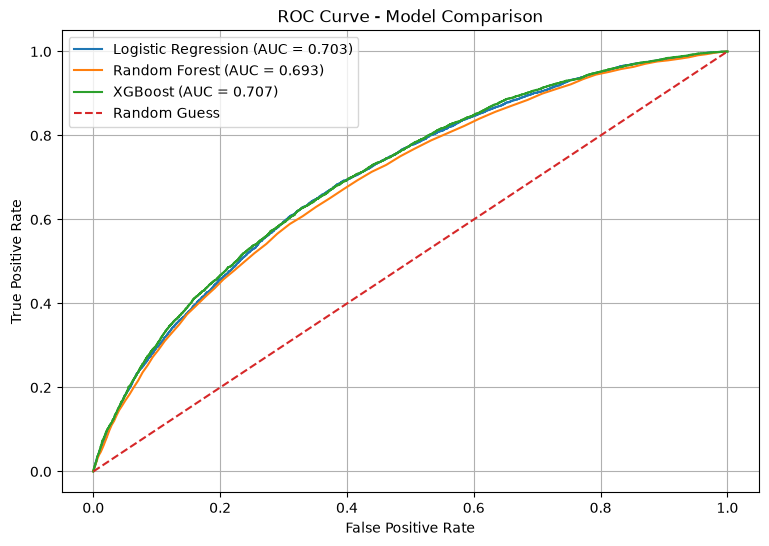

In [10]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_val)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_val, y_prob)

    auc_score = roc_auc_score(y_val, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Model Comparison")
plt.legend()
plt.grid()
plt.show()

In [11]:
from sklearn.metrics import precision_recall_curve

y_prob_xgb = trained_models["XGBoost"].predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_prob_xgb
)

valid_indices = np.where(recall[:-1] >= 0.75)[0]

if len(valid_indices) > 0:

    best_index = valid_indices[
        np.argmax(precision[:-1][valid_indices])
    ]

    best_threshold = thresholds[best_index]
    best_precision = precision[best_index]
    best_recall = recall[best_index]

    print("Selected Threshold:", best_threshold)
    print("Precision:", best_precision)
    print("Recall:", best_recall)

else:
    print("No threshold found with 75% recall.")

Selected Threshold: 0.17079951
Precision: 0.28805438653285853
Recall: 0.7503794906392309


In [14]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

X_tune = X_train.sample(
    n=30000,
    random_state=42
)

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20],
    "model__min_samples_split": [2, 5]
}

y_tune = y_train.loc[X_tune.index]

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_tune, y_tune)

print("Best Parameters:", rf_grid.best_params_)
print("Best F1 Score:", rf_grid.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters: {'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best F1 Score: 0.4256676378360586


In [15]:
from sklearn.model_selection import RandomizedSearchCV

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

xgb_params = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

print("XGBoost pipeline and parameters created!")

XGBoost pipeline and parameters created!


In [16]:
xgb_random = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=15,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1
)

xgb_random.fit(X_tune, y_tune)

print("Best Parameters:", xgb_random.best_params_)
print("Best F1 Score:", xgb_random.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best Parameters: {'model__subsample': 1.0, 'model__n_estimators': 300, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.8}
Best F1 Score: 0.15280259249849093


In [17]:
best_models = {
    "Tuned Random Forest": rf_grid.best_estimator_,
    "Tuned XGBoost": xgb_random.best_estimator_
}

for name, model in best_models.items():

    y_pred = model.predict(X_val)

    print("\n", name)
    print("Accuracy:", accuracy_score(y_val, y_pred))
    print("Precision:", precision_score(y_val, y_pred, zero_division=0))
    print("Recall:", recall_score(y_val, y_pred, zero_division=0))
    print("F1 Score:", f1_score(y_val, y_pred, zero_division=0))
    print("ROC-AUC:", roc_auc_score(
        y_val, model.predict_proba(X_val)[:, 1]
    ))


 Tuned Random Forest
Accuracy: 0.6440625958883093
Precision: 0.3138565651563918
Recall: 0.6414235115533817
F1 Score: 0.42147844397650447
ROC-AUC: 0.6999048464402186

 Tuned XGBoost
Accuracy: 0.7960519586785313
Precision: 0.47614761476147616
Recall: 0.08922246584584247
F1 Score: 0.15028409090909092
ROC-AUC: 0.6946295773668725


In [18]:
best_model = rf_grid.best_estimator_

rf_prob = best_model.predict_proba(X_val)[:, 1]

rf_precision, rf_recall, rf_thresholds = precision_recall_curve(
    y_val, rf_prob
)

valid_indices = np.where(rf_recall[:-1] >= 0.75)[0]

if len(valid_indices) > 0:

    best_index = valid_indices[
        np.argmax(rf_precision[:-1][valid_indices])
    ]

    final_threshold = rf_thresholds[best_index]

    print("Best Model: Tuned Random Forest")
    print("ROC-AUC:", roc_auc_score(y_val, rf_prob))
    print("Threshold:", final_threshold)
    print("Precision:", rf_precision[best_index])
    print("Recall:", rf_recall[best_index])

else:
    print("75% recall threshold not achieved.")

Best Model: Tuned Random Forest
ROC-AUC: 0.6999048464402186
Threshold: 0.4429149977292993
Precision: 0.2856867531800077
Recall: 0.7500421656265812


In [19]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_reg = df[regression_features]
y_reg = df["loan_amnt"]

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

regression_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

regression_pipeline.fit(X_reg_train, y_reg_train)

print("Regression model trained successfully!")
print("Training shape:", X_reg_train.shape)
print("Testing shape:", X_reg_test.shape)

Regression model trained successfully!
Training shape: (156432, 8)
Testing shape: (39109, 8)


In [20]:
reg_pred = regression_pipeline.predict(X_reg_test)

baseline_pred = np.full(
    len(y_reg_test),
    y_reg_train.mean()
)

for name, predictions in {
    "Linear Regression": reg_pred,
    "Mean Baseline": baseline_pred
}.items():

    mae = mean_absolute_error(y_reg_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_reg_test, predictions))
    r2 = r2_score(y_reg_test, predictions)

    print("\n", name)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)


 Linear Regression
MAE: 6053.01499471743
RMSE: 7929.712995040041
R2 Score: 0.16338859863773691

 Mean Baseline
MAE: 7039.675881406921
RMSE: 8669.541188057437
R2 Score: -2.46258251523912e-06


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

# Test probabilities
test_prob = best_model.predict_proba(X_test)[:, 1]

# Use threshold selected from validation data
test_pred = (test_prob >= final_threshold).astype(int)

print("Final Model: Tuned Random Forest")
print("Test Accuracy:", accuracy_score(y_test, test_pred))
print("Test Precision:", precision_score(y_test, test_pred))
print("Test Recall:", recall_score(y_test, test_pred))
print("Test F1 Score:", f1_score(y_test, test_pred))
print("Test ROC-AUC:", roc_auc_score(y_test, test_prob))
print("Confusion Matrix:\n", confusion_matrix(y_test, test_pred))

Final Model: Tuned Random Forest
Test Accuracy: 0.576708032183281
Test Precision: 0.2898879315929261
Test Recall: 0.7547647158036769
Test F1 Score: 0.41888982495553684
Test ROC-AUC: 0.7029799428259833
Confusion Matrix:
 [[12441 10962]
 [ 1454  4475]]


# Final Findings – Lending Club Results

## Classification
- Best Model: Tuned Random Forest
- Test Accuracy: 57.67%
- Test Precision: 28.99%
- Test Recall: 75.48%
- Test F1 Score: 41.89%
- Test ROC-AUC: 0.7030
- Selected threshold: 0.4429

## Hyperparameter Tuning
- Random Forest: GridSearchCV
- XGBoost: RandomizedSearchCV
- Random Forest achieved a better validation F1 score.

## Regression
- Model: Linear Regression
- MAE: 6053.01
- RMSE: 7929.71
- R² Score: 0.1634

## Conclusion
Tuned Random Forest was selected as the best classification model
based on validation performance. It achieved 75.48% recall on
the unseen test dataset, satisfying the minimum 75% recall target.

Linear Regression performed better than the mean baseline.